In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sys import argv

In [ ]:
data = pd.read_csv("/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv", sep='\t')
print(data.shape)
pd.crosstab(data["length"], data["class"])

(9728, 9)


class,0,1
length,,
40,2,0
42,1,0
44,1,0
45,2,0
46,2,3
...,...,...
8799,1,0
12345,1,0
18141,1,0


There are 1687 different lengths among all the proteins we have, so we need to build some bins for the graphs and rescale the data with the log because from the shortest to the longest there is really difference in length

In [84]:
# Soma descriptive statistics 
data.groupby('class')['length'].agg(['mean', 'median', 'var'])

,mean,median,var
class,,,
0,574.518205,425,487057.916171
1,398.953804,274,200611.839206


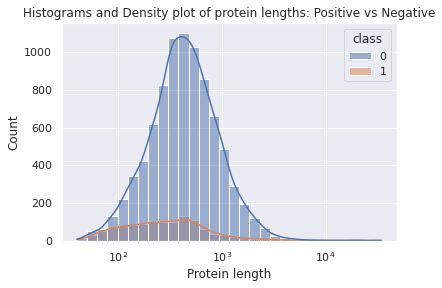

In [ ]:
sns.set_theme(context='notebook', style = 'darkgrid',
    palette= "deep", font='sant-serif', font_scale=1,
    color_codes= True, rc=None)

sns.histplot(data = data, x = "length", hue = "class",  log_scale = True, bins = 30, kde = True)

plt.xlabel("Protein length")
plt.ylabel("Count")
plt.title("Histograms and Density plot of protein lengths: Positive vs Negative")
plt.savefig('Protein_Length_hist_dens.svg', format='svg', bbox_inches='tight')
plt.show()

The plot shows that for the class 0 (negative) there are a lot of more data and follow a Normal distribution, with a mean of 574.5, which the positive class has a mean of 400. In the case of the positive proteins the distribution seems to be more large and vary mostly between 50 and 1000 aa, there isn't a bin with more entries, they are all quite similar.

Text(0.5, 1.0, 'Boxplot of protein lengths: Positive vs Negative')

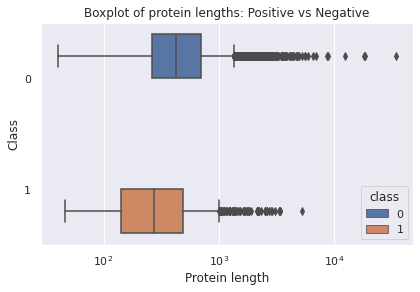

In [ ]:
sns.boxplot(data = data, y = "class", x = "length", hue = "class", orient = "h")
# legend and log_scale didnt work so i've done it manually
plt.xscale("log") 
plt.legend(title="class")
plt.ylabel("Class")
plt.xlabel("Protein length")
plt.tight_layout()
plt.title("Boxplot of protein lengths: Positive vs Negative")
plt.savefig('Protein_Length_box_posneg.svg', format='svg', bbox_inches='tight')


We've plotted the boxplot of the two classes, here we can see what said before, the negative class (0) has more data, in fact the boxplot is above the other one, and the mean and median are 574.5 and 425 respectively, while for the positive class are 400 and 274. Furthermore whiskers of the boxplot indicates that the class 0 has more variance, in fact in the left case is more than two times the right one.